<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">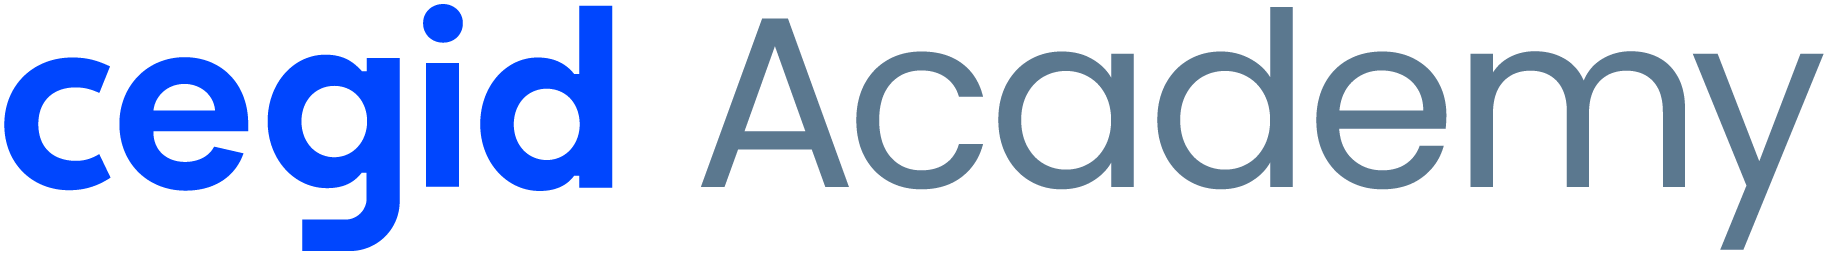<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 5 &middot; Avaliação</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Evaluation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M5</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| Projeto | Previsão da intenção de mudança de emprego |
| Grupo | Não indicado nos ficheiros fornecidos |
| Formandos | Não indicados nos ficheiros fornecidos |
| Data da revisão | 14/10/2026 |
| Dataset | `Data/input/Dados_RH_Mudanca_Emprego.csv` |

> **Versão atualizada após a entrega original.** A árvore de decisão e o Random Forest foram acrescentados em revisões posteriores. A escolha entre os três algoritmos usa apenas validação cruzada no treino.


<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Verificar se o modelo <b>resolve o problema de negócio</b> definido na Fase 1. A Fase 4 respondeu a “qual o melhor modelo?”; esta fase responde a <b>“o modelo é útil — ou apenas estatisticamente bom?”</b><ul style="margin:4px 0 2px 0;"><li>Métricas técnicas face aos critérios de sucesso</li><li>Análise de erros</li><li>Importância das variáveis e interpretação</li><li>Limitações, conclusões e recomendações</li></ul></div>

### 0. Configuração
<hr>

**0.1 Bibliotecas** — base, `joblib`, validação cruzada, métricas, `DummyClassifier`/`DummyRegressor` e (complemento) `permutation_importance`.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics
from sklearn.dummy import DummyClassifier


**0.2 Configuração** — ler `Data/output/config_projeto.json` (como no notebook 04).

In [2]:
config = json.loads(Path('Data/output/config_projeto.json').read_text(encoding='utf-8'))
PROJETO = config['PROJETO']
TARGET = config['TARGET']
FEATURES = config['RAW_FEATURES']
RANDOM_STATE = config['RANDOM_STATE']
SAIDA = Path('Data/output')
MODELOS = Path('Data/models')
ANALYTICS = Path('Data/analytics')


**0.3 Pastas** — as mesmas dos notebooks anteriores.

In [3]:
for pasta in [SAIDA, MODELOS, ANALYTICS]:
    pasta.mkdir(parents=True, exist_ok=True)


**0.4 Carregar o modelo e os dados**
- `joblib.load` do modelo final, o `.json` de metadados, a tabela de comparação, e os dados de treino/teste (ou o dataset de clustering).
- Calcular as previsões no teste (`y_pred`) ou os clusters (`labels`).

In [4]:
treino = pd.read_csv(SAIDA / f'{PROJETO}_train_raw.csv')
teste = pd.read_csv(SAIDA / f'{PROJETO}_test_raw.csv')
X_train, y_train = treino[FEATURES], treino[TARGET].astype(int)
X_test, y_test = teste[FEATURES], teste[TARGET].astype(int)
modelo_final = joblib.load(MODELOS / f'{PROJETO}_modelo_final.joblib')
metadados = json.loads((MODELOS / f'{PROJETO}_modelo_final.json').read_text(encoding='utf-8'))
LIMIAR = metadados['limiar']
prob_teste = modelo_final.predict_proba(X_test)[:, 1]
y_pred = (prob_teste >= LIMIAR).astype(int)

def calcular_metricas(real, previsto, probabilidade):
    return {
        'accuracy': metrics.accuracy_score(real, previsto),
        'precision': metrics.precision_score(real, previsto, zero_division=0),
        'recall': metrics.recall_score(real, previsto, zero_division=0),
        'f1': metrics.f1_score(real, previsto, zero_division=0),
        'roc_auc': metrics.roc_auc_score(real, probabilidade),
        'average_precision': metrics.average_precision_score(real, probabilidade)
    }


### 1. Relembrar o problema de negócio
<hr>

- Qual era o problema inicial e que decisão se pretende apoiar? (Fase 1, secções 2 e 3)
- Qual a métrica principal e qual o critério de sucesso definido?

**Objetivo:** garantir alinhamento com o problema de negócio.

**Resposta:** Estimamos a intenção declarada de procurar uma mudança de emprego. O F1 da classe Sim é a métrica principal. No notebook 04, a regressão logística, a árvore e o Random Forest foram comparados por validação cruzada no treino, com parâmetros fixos. Esta fase avalia o modelo escolhido, sem o alterar.


### 2. Resultados face aos critérios de sucesso

A tabela seguinte compara as metas definidas antes da modelação com os resultados reais de teste. Os critérios de interpretação e resposta ao negócio são discutidos nas secções 6 e 8.

**2.1 [Classificação] Métricas do modelo final no teste**
- Accuracy, precision, recall, F1 e ROC-AUC.

In [5]:
obtido = calcular_metricas(y_test, y_pred, prob_teste)
display(pd.Series(obtido, name='teste').round(3).to_frame())
criterios = pd.DataFrame([
    {'criterio': nome, 'meta': meta, 'resultado': obtido[nome],
     'cumprido': obtido[nome] >= meta}
    for nome, meta in config['METAS'].items()
])
display(criterios.round(3))
criterios.to_csv(SAIDA / f'{PROJETO}_criterios_sucesso.csv', index=False)


,teste
accuracy,0.757
precision,0.509
recall,0.746
f1,0.605
roc_auc,0.785
average_precision,0.512


,criterio,meta,resultado,cumprido
0,f1,0.50,0.605,True
1,recall,0.60,0.746,True
2,roc_auc,0.75,0.785,True


**Resposta:**

A tabela identifica cada meta cumprida ou não cumprida; atingir algumas metas não implica que o modelo esteja pronto para produção. A comparação com o baseline é apresentada na secção 5, e a utilidade no negócio depende também dos erros, da representatividade e da validação externa.

### 3. Análise de overfitting / underfitting e robustez
<hr>

- Existe grande diferença entre treino, validação cruzada e teste?
- O modelo é demasiado simples (underfitting) ou demasiado complexo (overfitting)?
- É **robusto** a pequenas variações dos dados? (desvio padrão na validação cruzada)

**3.1 [Classificação] Treino vs validação cruzada vs teste**
- Para accuracy e F1: score no treino, média e desvio da CV (treino) e score no teste; diagnóstico (treino − teste > 0,10).

In [6]:
# Comparar a avaliação com o treino e a validação cruzada.
resumo_robustez = pd.DataFrame({
    'treino': [metadados['metricas_treino']['f1']],
    'validacao_cruzada': [metadados['f1_cv']],
    'teste': [obtido['f1']]
}, index=['F1'])
display(resumo_robustez.round(3))


,treino,validacao_cruzada,teste
F1,0.624,0.618,0.605


**Resposta:**

A diferença entre treino, CV e teste ajuda a avaliar a generalização. Uma diferença acima de 0,10 é apenas um sinal prático de sobreajustamento, não uma regra universal. O desvio da CV descreve estes cinco folds; não mede incerteza sobre outros mercados ou períodos. A escolha de hiperparâmetros na mesma CV pode tornar o seu melhor score otimista.

### 4. Análise de erros
<hr>

**Classificação:** matriz de confusão (valores e percentagens), falsos positivos vs falsos negativos e o seu **custo para o negócio**, classes ou segmentos mais difíceis de prever.

**Regressão:** resíduos, erro por faixa de valores do target, maiores erros, erro por segmento.

**Objetivo:** compreender **onde e porquê** o modelo falha.

**4.1 [Classificação] Matriz de confusão**
- Em valores absolutos e normalizada por classe real (`normalize="true"`); em binário, contar VP, VN, FP e FN; `classification_report`.

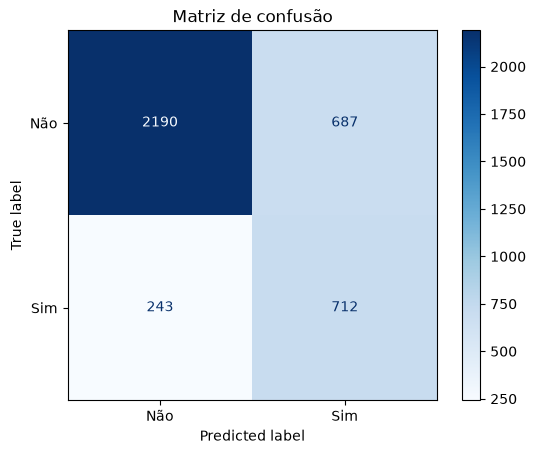

Falsos positivos: 687 | falsos negativos: 243


In [7]:
matriz = metrics.confusion_matrix(y_test, y_pred, labels=[0, 1])
vn, fp, fn, vp = matriz.ravel()
metrics.ConfusionMatrixDisplay(matriz, display_labels=['Não', 'Sim']).plot(cmap='Blues')
plt.title('Matriz de confusão')
plt.show()
print('Falsos positivos:', fp, '| falsos negativos:', fn)


**Resposta:**

O recall da classe Sim mostra a fração de candidatos positivos detetados; a matriz normalizada permite comparar as classes sem confundir os seus diferentes tamanhos. Os FP são falsos alertas e os FN são intenções não detetadas. Não existem custos monetários fornecidos: o custo total teria a forma FP × custo_FP + FN × custo_FN. Não atribuímos valores em euros sem dados.

**4.2 [Classificação] Erros por segmento**
- Criar uma coluna `erro` (real ≠ previsto) no teste e calcular a taxa de erro por categoria; listar alguns casos mal classificados.

In [8]:
# Verificar se há diferenças de erro por nível de educação.
erros = teste[['nivel_educacao']].copy()
erros['erro'] = y_test.to_numpy() != y_pred
resumo_erros = erros.groupby('nivel_educacao')['erro'].agg(['mean', 'count'])
display(resumo_erros.round(3))
resumo_erros.to_csv(SAIDA / f'{PROJETO}_erros_segmentos.csv')


,mean,count
nivel_educacao,,
Doutoramento,0.211,71
Ensino Básico,0.087,69
Ensino Secundário,0.292,397
Licenciatura,0.254,2304
Mestrado,0.213,888


**Resposta:**

As tabelas permitem localizar grupos com maior taxa de erro, menor recall ou mais falsos alarmes. As diferenças podem refletir tamanhos de amostra, prevalências, valores em falta e características não observadas; não demonstram a causa dos erros. O género é incluído nesta auditoria. Comparam-se apenas grupos com pelo menos 30 registos e não se conclui ausência de viés a partir de uma única amostra.

#### 4.1 (Complemento) Ajuste do limiar de decisão — classificação binária

Por defeito, o modelo prevê a classe positiva quando a probabilidade ≥ 0,5. Baixar o limiar aumenta o **recall** (menos falsos negativos) à custa da **precision**; subir faz o contrário. É o mesmo compromisso que se vê na curva ROC / Precision-Recall — a escolha depende do **custo de cada erro** no negócio.

O limiar é um hiperparâmetro: escolhê-lo a olhar para o teste é *data leakage* (o resultado reportado fica otimista). Escolhe-se com probabilidades obtidas por validação cruzada no treino e só depois se aplica ao teste.

<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>O ajuste do limiar não foi dado em aula. É uma extensão natural da curva ROC (M5): cada ponto da curva corresponde a um limiar diferente.</div>

**4.3 Sensibilidade ao limiar, apenas no treino**

Obtemos previsões fora do fold para ilustrar o compromisso precision/recall. O limiar operacional mantém-se em 0,50, conforme definido na Fase 1. Não se escolhe um novo limiar depois de ver o teste.

In [9]:
# O limiar já foi definido antes de avaliar o teste.
print('Limiar utilizado:', LIMIAR)


Limiar utilizado: 0.5


**Resposta:** Mantemos o limiar 0,50 definido na Fase 1. As curvas no treino ilustram o compromisso entre recall e precision.


### 5. Comparação com o baseline
<hr>

O modelo supera uma abordagem simples (prever sempre a classe maioritária / a média histórica)? Em quanto?

**Objetivo:** demonstrar valor acrescentado.

**5.1 Comparação com o baseline**

Comparamos F1 e Average Precision (AP) do modelo final com os do `DummyClassifier(strategy="most_frequent")` no teste.


In [10]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
prev_baseline = baseline.predict(X_test)
prob_baseline = baseline.predict_proba(X_test)[:, 1]
f1_baseline = metrics.f1_score(y_test, prev_baseline, zero_division=0)
ap_baseline = metrics.average_precision_score(y_test, prob_baseline)
comparacao_baseline = pd.DataFrame({
    'F1': [f1_baseline, obtido['f1']],
    'AP': [ap_baseline, obtido['average_precision']]
}, index=['Baseline', metadados['modelo']])
display(comparacao_baseline.round(3))


,F1,AP
Baseline,0.000,0.249
Random Forest,0.605,0.512


**Resposta:** O baseline prevê sempre Não e, por isso, tem recall e F1 iguais a zero para a classe Sim. A tabela compara também AP, completando o critério de superar o baseline definido na Fase 1.


### 6. Importância das variáveis e interpretação
<hr>

Que variáveis mais influenciam as previsões? A importância preditiva é diferente das associações observadas na Fase 2.

| Modelo | Como interpretar |
|---|---|
| Árvore de decisão / Random Forest | `feature_importances_` das colunas após a preparação |
| Regressão logística | `coef_` das colunas após a preparação |

O código lê o modelo final guardado pela Fase 4. A importância ajuda a descrever as previsões, sem provar causalidade.


**6.1 Importância das variáveis**

O código identifica o classificador guardado: para a árvore ou o Random Forest usa `feature_importances_`; para a logística usa o valor absoluto de `coef_`. A tabela mostra colunas transformadas após a preparação, não causas.


In [11]:
nomes = modelo_final.named_steps['prep'].get_feature_names_out()
classificador = modelo_final.named_steps['clf']
if hasattr(classificador, 'feature_importances_'):
    importancia = pd.DataFrame({
        'variavel': nomes,
        'importancia': classificador.feature_importances_
    }).sort_values('importancia', ascending=False)
    print('Importância das divisões da árvore; não mede causalidade.')
else:
    importancia = pd.DataFrame({
        'variavel': nomes,
        'coeficiente': classificador.coef_[0]
    })
    importancia['importancia'] = importancia['coeficiente'].abs()
    importancia = importancia.sort_values('importancia', ascending=False)
    print('Valor absoluto dos coeficientes; o sinal está na coluna coeficiente.')
display(importancia.head(10).round(3))
importancia.to_csv(SAIDA / f'{PROJETO}_importancia_variaveis.csv', index=False)


Importância das divisões da árvore; não mede causalidade.


,variavel,importancia
0,num__indice_desenvolvimento_cidade,0.228
68,cat__cidade_Zona_065,0.166
157,cat__dimensao_empresa_Desconhecido,0.112
159,cat__tipo_empresa_Desconhecido,0.085
160,cat__tipo_empresa_Empresa privada,0.063
1,num__anos_experiencia_num,0.054
133,cat__inscricao_universidade_Curso a tempo inteiro,0.032
141,cat__nivel_educacao_Licenciatura,0.020
145,cat__area_formacao_Desconhecido,0.015
131,cat__experiencia_relevante_Com experiência rel...,0.015


**Resposta:**

A importância nativa refere-se às colunas depois da preparação, incluindo cada categoria One-Hot. Nas árvores, mede contributos para divisões e pode favorecer variáveis com muitas possibilidades de corte; na logística, o sinal do coeficiente indica a direção condicionada às restantes variáveis. Estas medidas não demonstram causalidade. As hipóteses H1–H3 são discutidas com os resultados observacionais do notebook 02.

> **Complemento não executado:** a importância por permutação poderia avaliar os campos originais; esta versão usa apenas a importância nativa do modelo escolhido.

**6.2 Importância por permutação (não executada)**

Seria uma análise adicional nas variáveis originais. Nesta versão simples usamos apenas a importância nativa do modelo escolhido.


In [12]:
print('Não calculámos permutation importance; usamos a importância nativa do modelo final.')


Não calculámos permutation importance; usamos a importância nativa do modelo final.


**Resposta:** A importância nativa resume as colunas transformadas pelo pipeline. Para uma árvore, pode favorecer variáveis com muitas possibilidades de divisão. Não demonstra causalidade e não substitui uma auditoria de robustez.


### 7. Limitações do modelo
<hr>

- **Dados:** dimensão da amostra, período coberto, representatividade, qualidade
- **Modelo:** pressupostos, interpretabilidade, sensibilidade a outliers, estabilidade
- **Validação:** houve decisões tomadas depois de ver o teste? Há passos fora do Pipeline (seleção de variáveis, target encoding, capping) que tornam a CV otimista? Ficou algum risco de *data leakage* por resolver?
- **Viés e ética:** o modelo usa variáveis sensíveis (género, idade, estado civil)? Pode discriminar grupos? É aceitável usá-las na decisão?

**Objetivo:** reconhecer fragilidades.

**Resposta:** O CSV não documenta população, período, recolha ou licença, por isso não garante representatividade. O alvo mede intenção declarada de mudança, não saída efetiva. Há valores em falta e categorias raras.

Não foi feita pesquisa de hiperparâmetros nem validação aninhada.

O pré-processamento aprendido permanece dentro de cada fold. O género entra neste protótipo pedagógico e a auditoria por segmento não demonstra equidade. Uma utilização real exigiria verificar privacidade, autorização dos dados, calibração, impactos por grupo e revisão humana.


### 8. Conclusões e recomendações

| Questão | Resposta | Evidência |
|---|---|---|
| Q1: É possível prever a intenção? | O modelo supera o baseline, mas as metas e a generalização externa exigem avaliação crítica. | F1, recall, ROC-AUC, AP e matriz de confusão nas secções 2, 4 e 5. |
| Q2: Quais são os fatores associados? | A AED mostra associações; a importância preditiva do modelo é uma análise distinta. | Notebook 02 e tabela de importância nativa na secção 6. |
| Q3: Que perfis têm maior taxa? | Menor experiência, ausência de experiência relevante e inscrição universitária a tempo inteiro apresentam taxas superiores nesta amostra. | Taxas por categoria no notebook 02. |

H1 e H2 são apoiadas pela associação observada; H3 não é apoiada. Nenhuma destas análises demonstra causalidade.


**Recomendações:** usar os resultados para formular perguntas e ações voluntárias de desenvolvimento profissional, validar as conclusões com novos dados e comparar os erros por segmento. Investigar os fatores organizacionais em falta, como satisfação ou condições de trabalho, se existirem dados adequados. A intenção de mudança deve ser compreendida em diálogo com as pessoas; o score não fundamenta sozinho uma decisão individual.

### 9. Decisão final
<hr>

- O modelo é adequado para ser utilizado?
- **Avançar para Deployment** (Fase 6) ou **iterar** — voltar a que fase (1, 2, 3 ou 4) e para fazer o quê?
- Próximos passos (mais dados, novas variáveis, outros modelos)?

> Se iterarem depois de ver o teste, o teste deixa de ser “novo” para o modelo: registem-no e, se possível, confirmem o resultado com dados que não foram usados em nenhuma decisão (ex.: registos mais recentes).

**Objetivo:** concluir a fase de Evaluation.

**Resposta:** Avançamos apenas para um protótipo local de Deployment, com previsão em lote e revisão humana. Não há aprovação para uso real em RH. O modelo e o limiar são guardados sem novas alterações após esta avaliação. Para confirmar a versão atualizada, precisamos de dados novos e de uma auditoria de qualidade, calibração, privacidade e desempenho por segmentos.


In [13]:
resumo = {
    'versao': metadados['versao'],
    'modelo': metadados['modelo'],
    'metricas_teste': obtido,
    'f1_cv': metadados['f1_cv'],
    'matriz': {'vn': int(vn), 'fp': int(fp), 'fn': int(fn), 'vp': int(vp)},
    'metas_numericas_cumpridas': bool(criterios['cumprido'].all()),
    'baseline_f1_e_ap_superados': bool(
        obtido['f1'] > f1_baseline and obtido['average_precision'] > ap_baseline
    )
}
(SAIDA / f'{PROJETO}_resumo_validado.json').write_text(
    json.dumps(resumo, ensure_ascii=False, indent=2), encoding='utf-8'
)
print('Resumo guardado.')


Resumo guardado.


<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Métricas de avaliação adequadas e comparadas com os critérios de sucesso</li><li>Interpretação dos resultados (falsos positivos/negativos, resíduos, overfitting)</li><li>Escolha do melhor modelo fundamentada e comparada com o baseline</li><li>Análise da importância das variáveis</li><li>Limiar de decisão (se ajustado) escolhido sem usar o teste</li><li>Limitações e possíveis enviesamentos identificados</li><li>Conclusões e recomendações práticas para o negócio</li></ul></div>

[← Fase 4: Modelação](04_P_modeling.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 6: Deployment →](06_P_deployment.ipynb)
